In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tspg13/houseprice/HousePriceDataset.csv


In [2]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [3]:
class LinearRegression:

    def __init__(self, learning_rate=0.01, epochs=1000):

        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = None

        self.loss_history = []


    # =====================================================
    # Prediction Function
    # =====================================================

    def predict(self, X):

        return np.dot(X, self.weights) + self.bias


    # =====================================================
    # Mean Squared Error
    # =====================================================

    def mse(self, y_true, y_pred):

        return np.mean((y_true - y_pred) ** 2)


    # =====================================================
    # GRADIENT TRAINING FUNCTION
    # =====================================================

    def gradient_train(self, X, y):

        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []
        # Gradient Descent
        for epoch in range(self.epochs):

            # 1. Prediction
            y_pred = self.predict(X)

            # 2. Error
            error = y_pred - y

            # 3. Calculate gradients
            dw = (2 / n_samples) * np.dot(X.T, error)

            db = (2 / n_samples) * np.sum(error)

            # 4. Update weights and bias
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # 5. Make new prediction after updating parameters
            y_pred = self.predict(X)

            # 6. Calculate loss after the update
            loss = self.mse(y, y_pred)
            self.loss_history.append(loss)

        return self


    # =====================================================
    # R² SCORE
    # =====================================================

    def r2_score(self, y_true, y_pred):

        ss_total = np.sum(
            (y_true - np.mean(y_true)) ** 2
        )

        ss_residual = np.sum(
            (y_true - y_pred) ** 2
        )

        return 1 - (ss_residual / ss_total)


In [4]:
# =========================================================
# TRAINING FUNCTION
# =========================================================

def train(model, X_train, y_train):

    model.gradient_train(
        X_train,
        y_train
    )

    return model


In [5]:
def test(model, X_test, y_test):

    # Predict in log scale
    y_pred_log = model.predict(X_test)

    # Convert prediction back to original price scale
    y_pred = np.expm1(y_pred_log)

    # Convert actual test values back to original price scale
    y_actual = np.expm1(y_test)

    # Calculate metrics
    mse = model.mse(
        y_actual,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = model.r2_score(
        y_actual,
        y_pred
    )

    print("Testing Results")
    print("----------------")
    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("R²   :", r2)

    return y_actual, y_pred, mse, rmse, r2

In [6]:
path="/kaggle/input/datasets/tspg13/houseprice/HousePriceDataset.csv"
df = pd.read_csv(path)


In [7]:
#Replace whitespaces, mutilple hypens etc with one single whitespace.
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29451 entries, 0 to 29450
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   posted_by             29451 non-null  object 
 1   under_construction    29451 non-null  int64  
 2   rera                  29451 non-null  int64  
 3   bhk_no                29451 non-null  int64  
 4   bhk_or_rk             29451 non-null  object 
 5   square_ft             29451 non-null  float64
 6   ready_to_move         29451 non-null  int64  
 7   resale                29451 non-null  int64  
 8   address               29451 non-null  object 
 9   longitude             29451 non-null  float64
 10  latitude              29451 non-null  float64
 11  target_price_in_lacs  29451 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 2.7+ MB


In [9]:
df.describe()


,under_construction,rera,bhk_no,square_ft,ready_to_move,resale,longitude,latitude,target_price_in_lacs
count,29451.000000,29451.000000,29451.000000,2.945100e+04,29451.000000,29451.000000,29451.000000,29451.000000,29451.000000
mean,0.179756,0.317918,2.392279,1.980217e+04,0.820244,0.929578,21.300255,76.837695,142.898746
std,0.383991,0.465675,0.879091,1.901335e+06,0.383991,0.255861,6.205306,10.557747,656.880713
min,0.000000,0.000000,1.000000,3.000000e+00,0.000000,0.000000,-37.713008,-121.761248,0.250000
25%,0.000000,0.000000,2.000000,9.000211e+02,1.000000,1.000000,18.452663,73.798100,38.000000
50%,0.000000,0.000000,2.000000,1.175057e+03,1.000000,1.000000,20.750000,77.324137,62.000000
75%,0.000000,1.000000,3.000000,1.550688e+03,1.000000,1.000000,26.900926,77.828740,100.000000
max,1.000000,1.000000,20.000000,2.545455e+08,1.000000,1.000000,59.912884,152.962676,30000.000000


In [10]:
#Checking sum of null values in each column
df.isna().sum()


posted_by               0
under_construction      0
rera                    0
bhk_no                  0
bhk_or_rk               0
square_ft               0
ready_to_move           0
resale                  0
address                 0
longitude               0
latitude                0
target_price_in_lacs    0
dtype: int64

In [11]:
categorical_cols=['posted_by','bhk_or_rk']
for column in categorical_cols:
    df[column] = df[column].str.strip().str.lower()


In [12]:
for column in categorical_cols:
    print(f"\nColumn: {column}")
    print(f"Number of unique values: {df[column].nunique()}")
    print("Unique values:")
    print(df[column].unique())
    print(f"\nColumn: {column}")
    print(df[column].value_counts())



Column: posted_by
Number of unique values: 3
Unique values:
['owner' 'dealer' 'builder']

Column: posted_by
posted_by
dealer     18291
owner      10538
builder      622
Name: count, dtype: int64

Column: bhk_or_rk
Number of unique values: 2
Unique values:
['bhk' 'rk']

Column: bhk_or_rk
bhk_or_rk
bhk    29427
rk        24
Name: count, dtype: int64


In [13]:
ohe= OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore',
    drop='first'
)
ohe.set_output(transform="pandas")


OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

In [14]:
encoded_df = ohe.fit_transform(df[categorical_cols])


In [15]:
final_df = pd.concat(
    [df.drop(columns=categorical_cols), encoded_df],
    axis=1
)


In [16]:
final_df.dtypes

num_cols=['rera','bhk_no', 'square_ft','resale','longitude','latitude']

In [17]:
for col in num_cols:
    Q1 = final_df[col].quantile(0.25)
    Q3 = final_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    final_df = final_df[
        (final_df[col] >= lower_bound) &
        (final_df[col] <= upper_bound)
    ]


In [18]:
X = final_df.drop(
    columns=['address', 'target_price_in_lacs']
)

y = final_df['target_price_in_lacs'].values

# original target for evaluation/plotting
y_original = y.copy()

# Log-transform target
y = np.log1p(y)

In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=42)


In [20]:
scaler = StandardScaler()

num_cols = [
    'rera',
    'bhk_no',
    'square_ft',
    'resale',
    'longitude',
    'latitude'
]

# Log-transform highly skewed feature
X_train['square_ft'] = np.log1p(
    X_train['square_ft']
)

X_test['square_ft'] = np.log1p(
    X_test['square_ft']
)

# Standardize numerical features
X_train[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

X_test[num_cols] = scaler.transform(
    X_test[num_cols]
)

X_train = X_train.values
X_test = X_test.values

In [21]:
model = LinearRegression(
    learning_rate=0.01,
    epochs=10000
)

model = train(
    model,
    X_train,
    y_train
)


In [22]:
print("Weights:", model.weights)
print("Bias:", model.bias)


Weights: [ 1.05063928  0.03448451  0.1506763   0.26097278  1.01635909  0.
 -0.17084174 -0.14113103  1.2479851   0.78339703  0.07508282]
Bias: 2.0669983624692496


In [23]:
# =========================================================
# TRAINING RESULTS
# =========================================================

# Prediction in log scale
y_train_pred_log = model.predict(X_train)

# Convert to original price scale
y_train_pred = np.expm1(
    y_train_pred_log
)

y_train_actual = np.expm1(
    y_train
)

# Calculate metrics
train_mse = model.mse(
    y_train_actual,
    y_train_pred
)

train_rmse = np.sqrt(
    train_mse
)

train_r2 = model.r2_score(
    y_train_actual,
    y_train_pred
)

print("\nTraining Results")
print("----------------")
print("MSE :", train_mse)
print("RMSE:", train_rmse)
print("R²  :", train_r2)


Training Results
----------------
MSE : 8842.582227918223
RMSE: 94.03500533268567
R²  : 0.21067767763166756


In [24]:
# =========================================================
# TESTING
# =========================================================

y_test_actual, y_test_pred, test_mse, test_rmse, test_r2 = test(
    model,
    X_test,
    y_test
)

Testing Results
----------------
MSE  : 8629.982592390597
RMSE : 92.89769960763613
R²   : 0.239430671176718


In [25]:
print("Training MSE:", train_mse)
print("Testing MSE:", test_mse)
print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)
print("Training R²:", train_r2)
print("Testing R²:", test_r2)


Training MSE: 8842.582227918223
Testing MSE: 8629.982592390597
Training RMSE: 94.03500533268567
Testing RMSE: 92.89769960763613
Training R²: 0.21067767763166756
Testing R²: 0.239430671176718


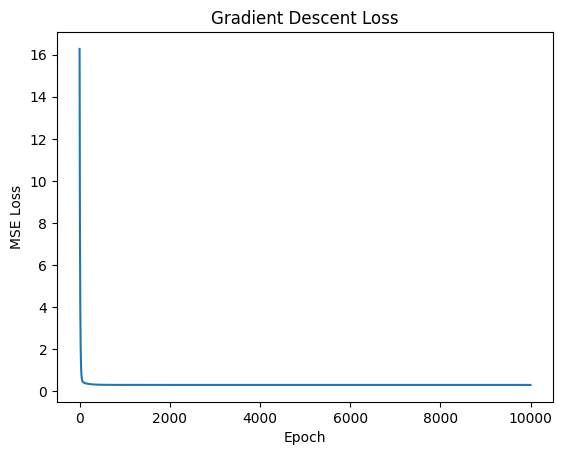

In [26]:
plt.plot(model.loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title("Gradient Descent Loss")

plt.show()


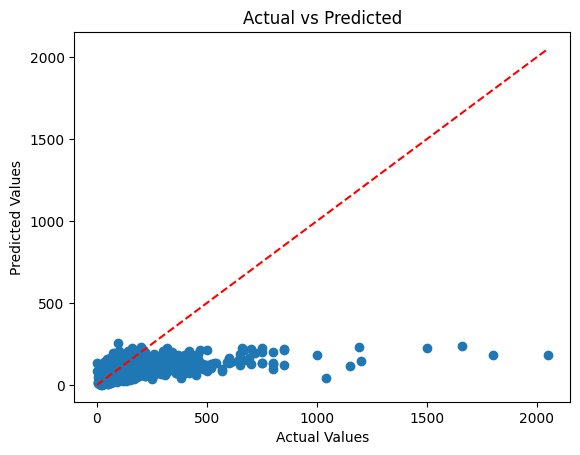

In [27]:
plt.scatter(
    y_test_actual,
    y_test_pred
)

min_val = min(
    y_test_actual.min(),
    y_test_pred.min()
)

max_val = max(
    y_test_actual.max(),
    y_test_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.show()